In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.shape)

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df = df.dropna(subset=["TotalCharges"])
df = df.drop("customerID", axis=1)
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})
df.to_csv("data/cleaned_churn.csv", index=False)
print(df.shape, df["Churn"].isna().sum())

(7043, 21)
(7032, 20) 0


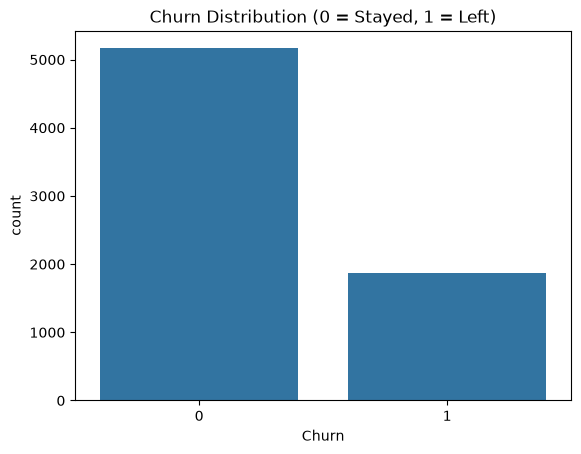

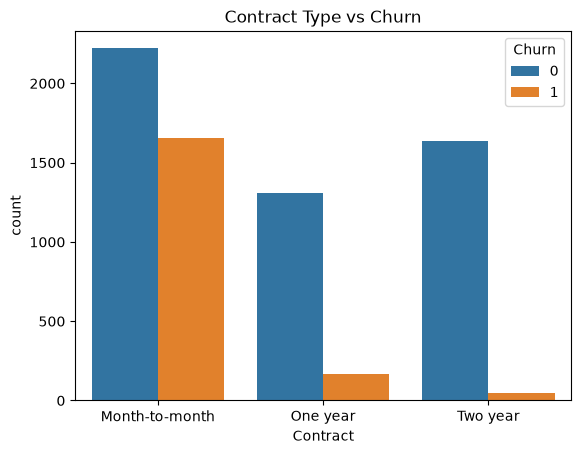

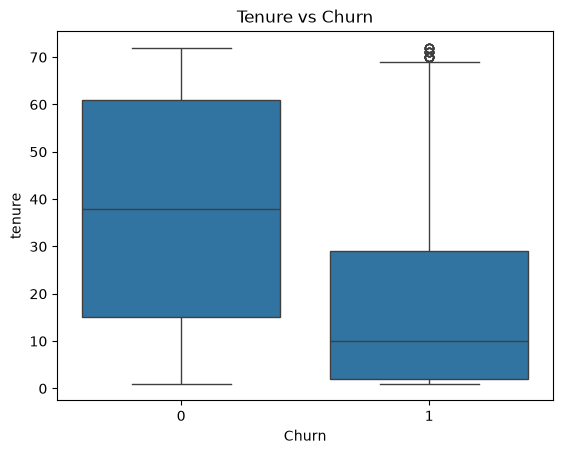

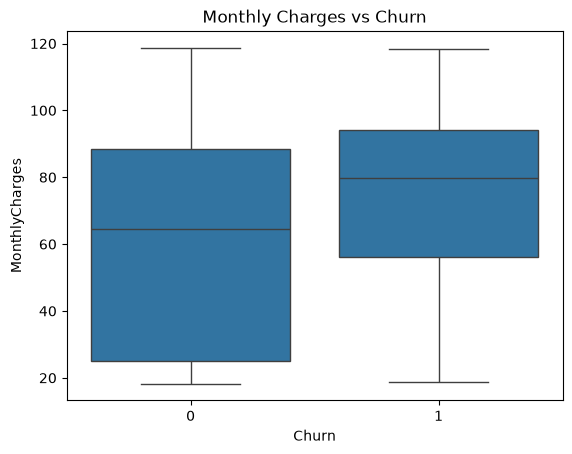

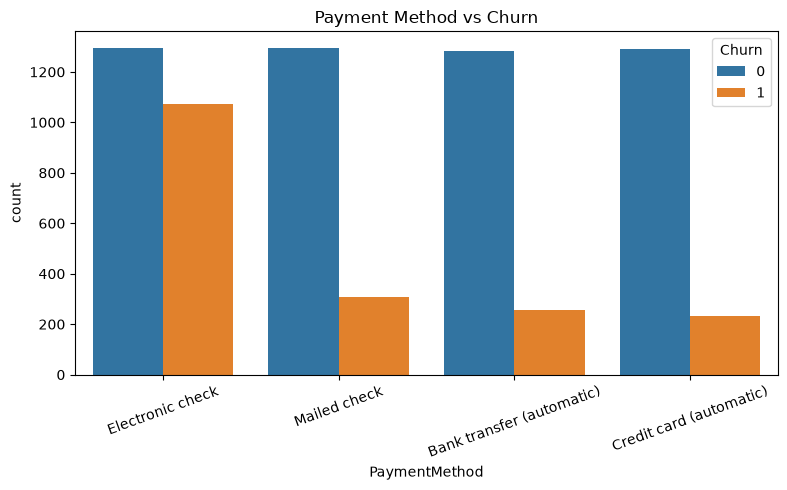

In [2]:
sns.countplot(x="Churn", data=df)
plt.title("Churn Distribution (0 = Stayed, 1 = Left)")
plt.savefig("images/churn_distribution.png")
plt.show()

sns.countplot(x="Contract", hue="Churn", data=df)
plt.title("Contract Type vs Churn")
plt.savefig("images/contract_vs_churn.png")
plt.show()

sns.boxplot(x="Churn", y="tenure", data=df)
plt.title("Tenure vs Churn")
plt.savefig("images/tenure_vs_churn.png")
plt.show()

sns.boxplot(x="Churn", y="MonthlyCharges", data=df)
plt.title("Monthly Charges vs Churn")
plt.savefig("images/monthly_vs_churn.png")
plt.show()

plt.figure(figsize=(8,5))
sns.countplot(x="PaymentMethod", hue="Churn", data=df)
plt.xticks(rotation=20)
plt.title("Payment Method vs Churn")
plt.tight_layout()
plt.savefig("images/payment_vs_churn.png")
plt.show()

In [3]:
print("Churn rate:", round(df["Churn"].mean()*100, 2), "%")
print(df.groupby("Contract")["Churn"].mean().round(3))
print(df.groupby("InternetService")["Churn"].mean().round(3))
print(df.groupby("PaymentMethod")["Churn"].mean().round(3))

Churn rate: 26.58 %
Contract
Month-to-month    0.427
One year          0.113
Two year          0.028
Name: Churn, dtype: float64
InternetService
DSL            0.190
Fiber optic    0.419
No             0.074
Name: Churn, dtype: float64
PaymentMethod
Bank transfer (automatic)    0.167
Credit card (automatic)      0.153
Electronic check             0.453
Mailed check                 0.192
Name: Churn, dtype: float64


In [4]:
from sklearn.model_selection import train_test_split

df_model = pd.get_dummies(df, drop_first=True)
X = df_model.drop("Churn", axis=1)
y = df_model["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)

(5625, 30) (1407, 30)


In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "Logistic Regression (balanced)": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")
    ),
}

results = []
for name, m in models.items():
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    prob = m.predict_proba(X_test)[:, 1]
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob),
    })

pd.DataFrame(results).round(3)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.804,0.648,0.575,0.609,0.836
1,Random Forest,0.787,0.621,0.508,0.559,0.818
2,Logistic Regression (balanced),0.726,0.491,0.797,0.608,0.835


In [6]:
import joblib, os
os.makedirs("models", exist_ok=True)
joblib.dump(models["Logistic Regression"], "models/churn_model.pkl")
joblib.dump(models["Logistic Regression (balanced)"], "models/churn_model_balanced.pkl")

['models/churn_model_balanced.pkl']

In [7]:
model = joblib.load("models/churn_model.pkl")
sample = X_test.iloc[[0]]

prob = model.predict_proba(sample)[0][1]
pred = model.predict(sample)[0]

print(f"Churn probability: {prob:.2%}")
print("Prediction:", "Churn avthadu" if pred == 1 else "Churn avvadu")
print("Actual:", "Churn" if y_test.iloc[0] == 1 else "No churn")

Churn probability: 1.71%
Prediction: Churn avvadu
Actual: No churn


In [8]:
test_results = X_test.copy()
test_results["Churn_Probability"] = model.predict_proba(X_test)[:, 1]
test_results["Actual"] = y_test.values
test_results.sort_values("Churn_Probability", ascending=False).head(10)[["Churn_Probability", "Actual"]]

,Churn_Probability,Actual
3380,0.847428,1
3159,0.846212,0
2631,0.828196,1
4585,0.822446,1
582,0.817107,1
2797,0.815147,1
3727,0.813745,1
933,0.811263,1
6240,0.796931,1
5213,0.795470,0


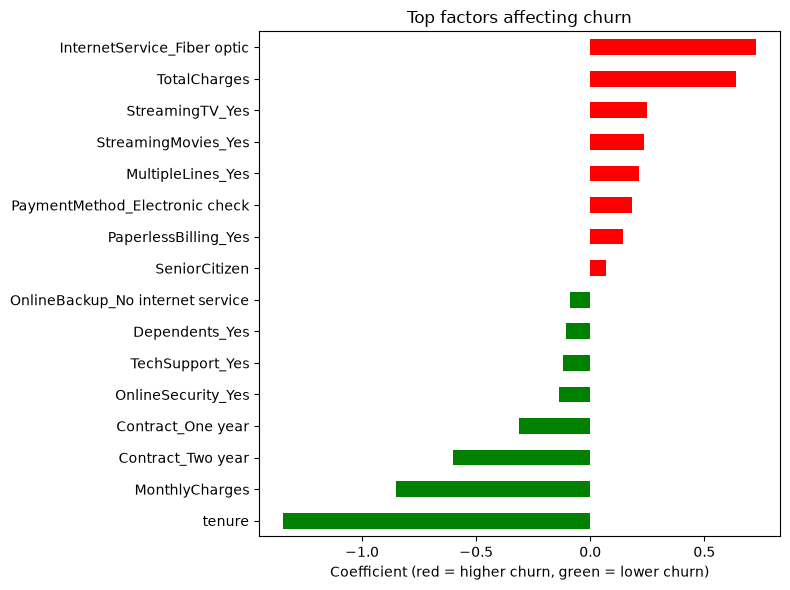

In [9]:
coefs = model.named_steps["logisticregression"].coef_[0]
importance = pd.Series(coefs, index=X.columns).sort_values()
top = pd.concat([importance.head(8), importance.tail(8)])

plt.figure(figsize=(8, 6))
top.plot(kind="barh", color=["green" if v < 0 else "red" for v in top])
plt.title("Top factors affecting churn")
plt.xlabel("Coefficient (red = higher churn, green = lower churn)")
plt.tight_layout()
plt.savefig("images/model_feature_importance.png", dpi=150)
plt.show()